## Exploratory Data Analysis

Studying the relationship between the features and target variables

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

df = pd.read_csv("../data/raw/dataset.csv")
df.shape, df.columns

((1600, 24),
 Index(['variation_id', 'gene_symbol', 'protein_change', 'protein_position',
        'ref_aa', 'alt_aa', 'clinical_significance', 'domain', 'plddt',
        'is_stop_gained', 'is_frameshift', 'is_splice_region', 'label',
        'pos_norm', 'distance_to_domain', 'plddt_at_pos', 'plddt_window11',
        'hydro_delta', 'charge_delta', 'volume_delta', 'domain_BRCT1',
        'domain_BRCT2', 'domain_OTHER', 'domain_RING'],
       dtype='str'))

In [3]:
df["label"].value_counts().sort_index(), df["label"].value_counts(normalize=True).sort_index().mul(100).round(2)

(label
 0    939
 1    661
 Name: count, dtype: int64,
 label
 0    58.69
 1    41.31
 Name: proportion, dtype: float64)

Benign/Likely Benign - 58.7 % <br>
Pathogenic/Likely Pathogenic - 41.3 %

there is a moderate class imbalance

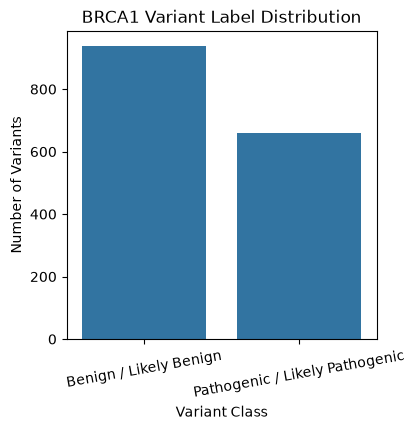

In [4]:
label_names = {0: "Benign / Likely Benign", 1: "Pathogenic / Likely Pathogenic"}
label_counts = (df["label"].map(label_names).value_counts())

plt.figure(figsize=(4, 4))
sns.barplot(x=label_counts.index,y=label_counts.values)
plt.xlabel("Variant Class")
plt.ylabel("Number of Variants")
plt.title("BRCA1 Variant Label Distribution")
plt.xticks(rotation=10)
plt.show()

In [5]:
df.groupby("label")["protein_position"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,939.0,940.77,496.67,7.0,501.0,961.0,1366.0,1857.0
1,661.0,926.88,607.10,1.0,354.0,942.0,1512.0,1861.0


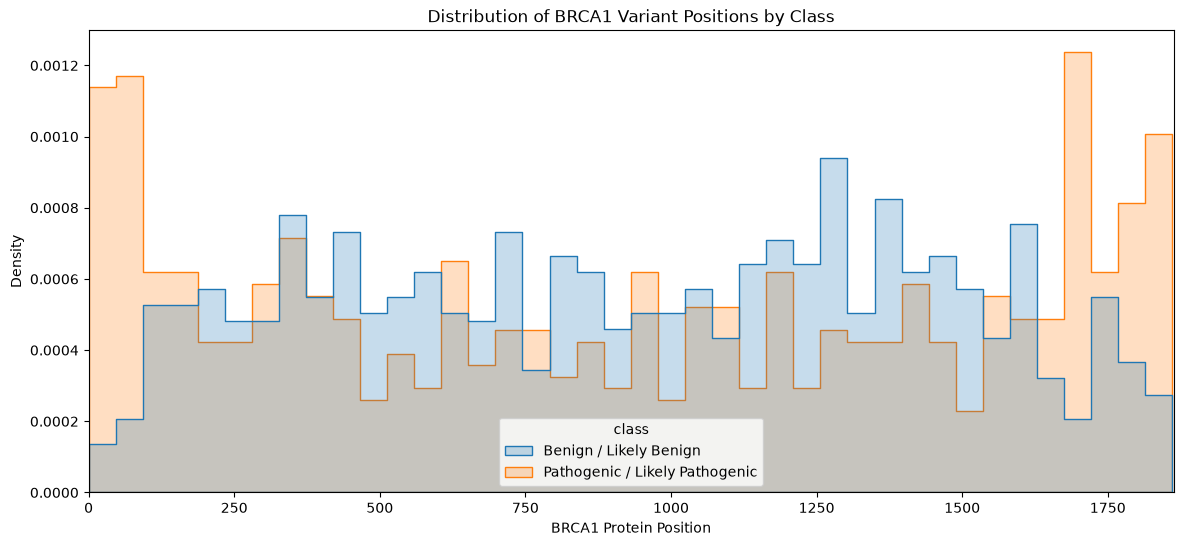

In [6]:
plot_df = df.copy()
plot_df["class"] = plot_df["label"].map(label_names)

plt.figure(figsize=(14, 6))
sns.histplot(data=plot_df,x="protein_position",hue="class",bins=40,element="step",stat="density",common_norm=False)
plt.xlim(0, 1863)
plt.xlabel("BRCA1 Protein Position")
plt.ylabel("Density")
plt.title("Distribution of BRCA1 Variant Positions by Class")
plt.show()

In [7]:
pd.crosstab(df["domain"],df["label"])

label,0,1
domain,,
BRCT1,21,54
BRCT2,32,58
OTHER,869,468
RING,17,81


In [8]:
domain_class_pct = (pd.crosstab(df["domain"],df["label"],normalize="index").mul(100).round(1))
domain_class_pct = domain_class_pct.rename(columns={0: "Benign / Likely Benign",1: "Pathogenic / Likely Pathogenic"})
domain_class_pct

label,Benign / Likely Benign,Pathogenic / Likely Pathogenic
domain,,
BRCT1,28.0,72.0
BRCT2,35.6,64.4
OTHER,65.0,35.0
RING,17.3,82.7


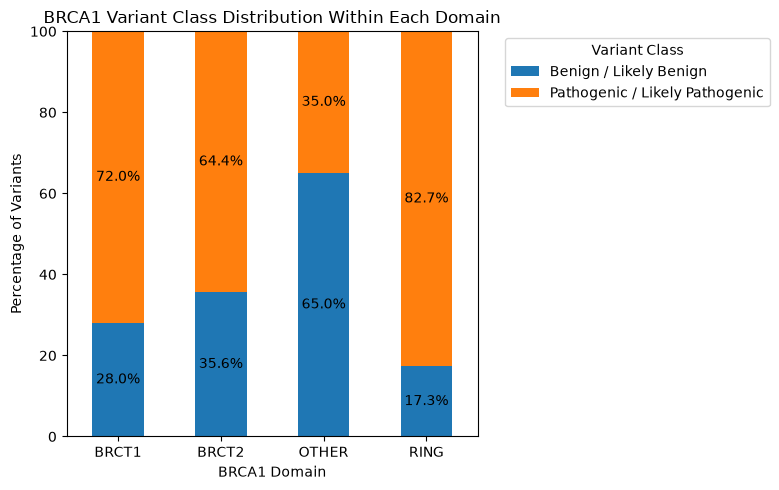

In [9]:
ax = domain_class_pct.plot(kind="bar",stacked=True,figsize=(8, 5))

for container in ax.containers:
    ax.bar_label(container,fmt="%.1f%%",label_type="center")

plt.xlabel("BRCA1 Domain")
plt.ylabel("Percentage of Variants")
plt.title("BRCA1 Variant Class Distribution Within Each Domain")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title="Variant Class",bbox_to_anchor=(1.05, 1),loc="upper left")
plt.tight_layout()
plt.show()

In [10]:
structural_cols = ["plddt","plddt_at_pos","plddt_window11"]
df.groupby("label")[structural_cols].agg(["mean", "median", "std", "min", "max"]).round(2)

plddt                            plddt_at_pos                       \
        mean median    std    min   max         mean median    std    min   
label                                                                       
0      54.42  52.98  12.25  26.59  98.0        54.44  52.78  11.85  31.93   
1      62.18  56.96  17.75  30.39  98.0        62.21  56.73  17.15  27.90   

            plddt_window11                              
        max           mean median    std    min    max  
label                                                   
0      98.0          54.39  52.65  10.26  39.87  92.83  
1      98.0          61.96  57.30  16.20  41.26  93.29

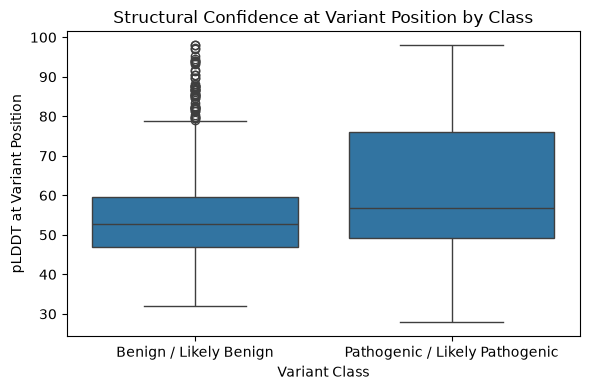

In [11]:
eda_df = df.copy()
eda_df["class"] = eda_df["label"].map(label_names)

plt.figure(figsize=(6, 4))
sns.boxplot(data=eda_df,x="class",y="plddt_at_pos")
plt.xlabel("Variant Class")
plt.ylabel("pLDDT at Variant Position")
plt.title("Structural Confidence at Variant Position by Class")
plt.tight_layout()
plt.show()

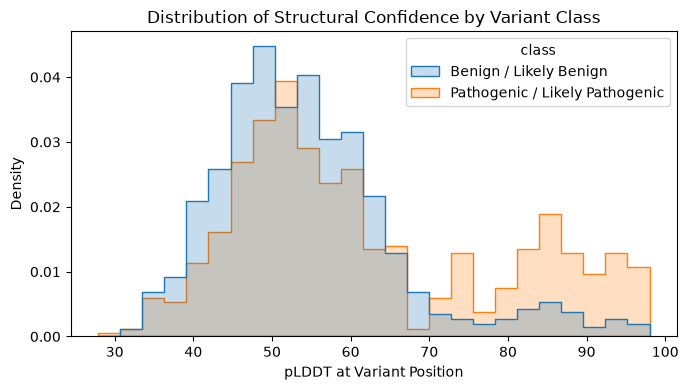

In [12]:
# Normalized histogram to compare the pLDDT values across class labels (common_norm=False, as 2 classes have different scales)

plt.figure(figsize=(7, 4))
sns.histplot(data=eda_df,x="plddt_at_pos",hue="class",bins=25,stat="density",common_norm=False,element="step")
plt.xlabel("pLDDT at Variant Position")
plt.ylabel("Density")
plt.title("Distribution of Structural Confidence by Variant Class")
plt.tight_layout()
plt.show()

In [13]:
domain_plddt_smry = (eda_df.groupby(["domain", "class"])["plddt_at_pos"].agg(["count", "mean", "median", "std"]).round(2))
domain_plddt_smry

count   mean  median   std
domain class                                                     
BRCT1  Benign / Likely Benign             21  88.79   87.64  5.34
       Pathogenic / Likely Pathogenic     54  90.23   90.82  5.65
BRCT2  Benign / Likely Benign             32  81.29   81.90  6.07
       Pathogenic / Likely Pathogenic     58  79.43   79.25  5.01
OTHER  Benign / Likely Benign            869  51.99   51.92  8.21
       Pathogenic / Likely Pathogenic    468  52.42   52.43  8.08
RING   Benign / Likely Benign             17  86.63   86.74  7.04
       Pathogenic / Likely Pathogenic     81  87.75   88.59  6.38

In [14]:
df.groupby("label")[["hydro_delta", "charge_delta", "volume_delta"]].agg(["mean", "median", "std"]).round(2)

hydro_delta              charge_delta              volume_delta         \
             mean median   std         mean median   std         mean median   
label                                                                          
0            3.28    2.8  2.44         0.45    0.0  0.56        45.92   40.4   
1            3.82    3.2  2.43         0.52    0.0  0.58        51.89   51.4   

              
         std  
label         
0      33.04  
1      33.56

In [15]:
charge_class = pd.crosstab(df["charge_delta"],df["label"],normalize="index").mul(100).round(1)
charge_class

label,0,1
charge_delta,,
0,61.3,38.7
1,56.0,44.0
2,49.2,50.8


In [16]:
subs_class = (df.groupby(["ref_aa", "alt_aa"])
                      .agg(n_variants=("variation_id", "count"),pathogenic_rate=("label", "mean"))
                      .sort_values("n_variants", ascending=False))

subs_class.head(10)

,,n_variants,pathogenic_rate
ref_aa,alt_aa,,
L,C,12,0.500000
N,Q,11,0.272727
L,Q,11,0.363636
Y,D,11,0.181818
Q,C,10,0.300000
R,S,9,0.666667
W,H,9,0.555556
K,V,9,0.444444
N,V,9,0.555556


In [17]:
for col in ["is_stop_gained", "is_frameshift", "is_splice_region"]:
    display(pd.crosstab(df[col],df["label"],normalize="index").mul(100).round(1))

label,0,1
is_stop_gained,,
0,62.9,37.1
1,15.4,84.6


label,0,1
is_frameshift,,
0,62.9,37.1
1,21.6,78.4


label,0,1
is_splice_region,,
0,61.2,38.8
1,16.7,83.3


## Correlations

### Numerical

In [18]:
numeric_cols = ["protein_position","plddt","label","pos_norm","distance_to_domain","plddt_at_pos","plddt_window11",
                "hydro_delta","charge_delta","volume_delta","is_stop_gained","is_frameshift","is_splice_region"]

corr_matrix = df[numeric_cols].corr()
corr_matrix.round(2)

,protein_position,plddt,label,pos_norm,distance_to_domain,plddt_at_pos,plddt_window11,hydro_delta,charge_delta,volume_delta,is_stop_gained,is_frameshift,is_splice_region
protein_position,1.00,0.08,-0.01,1.00,-0.12,0.08,0.08,-0.01,0.01,-0.07,-0.02,-0.03,0.01
plddt,0.08,1.00,0.25,0.08,-0.50,0.84,0.90,-0.01,-0.02,-0.03,-0.01,0.04,-0.01
label,-0.01,0.25,1.00,-0.01,-0.17,0.26,0.27,0.11,0.06,0.09,0.28,0.25,0.21
pos_norm,1.00,0.08,-0.01,1.00,-0.12,0.08,0.08,-0.01,0.01,-0.07,-0.02,-0.03,0.01
distance_to_domain,-0.12,-0.50,-0.17,-0.12,1.00,-0.52,-0.56,0.01,0.02,-0.00,0.00,-0.01,-0.01
plddt_at_pos,0.08,0.84,0.26,0.08,-0.52,1.00,0.92,-0.03,-0.02,-0.03,0.01,0.04,-0.02
plddt_window11,0.08,0.90,0.27,0.08,-0.56,0.92,1.00,-0.02,-0.02,-0.03,0.00,0.04,-0.01
hydro_delta,-0.01,-0.01,0.11,-0.01,0.01,-0.03,-0.02,1.00,0.10,-0.17,0.03,-0.00,-0.02
charge_delta,0.01,-0.02,0.06,0.01,0.02,-0.02,-0.02,0.10,1.00,-0.10,-0.03,-0.02,-0.01
volume_delta,-0.07,-0.03,0.09,-0.07,-0.00,-0.03,-0.03,-0.17,-0.10,1.00,0.05,-0.01,0.02


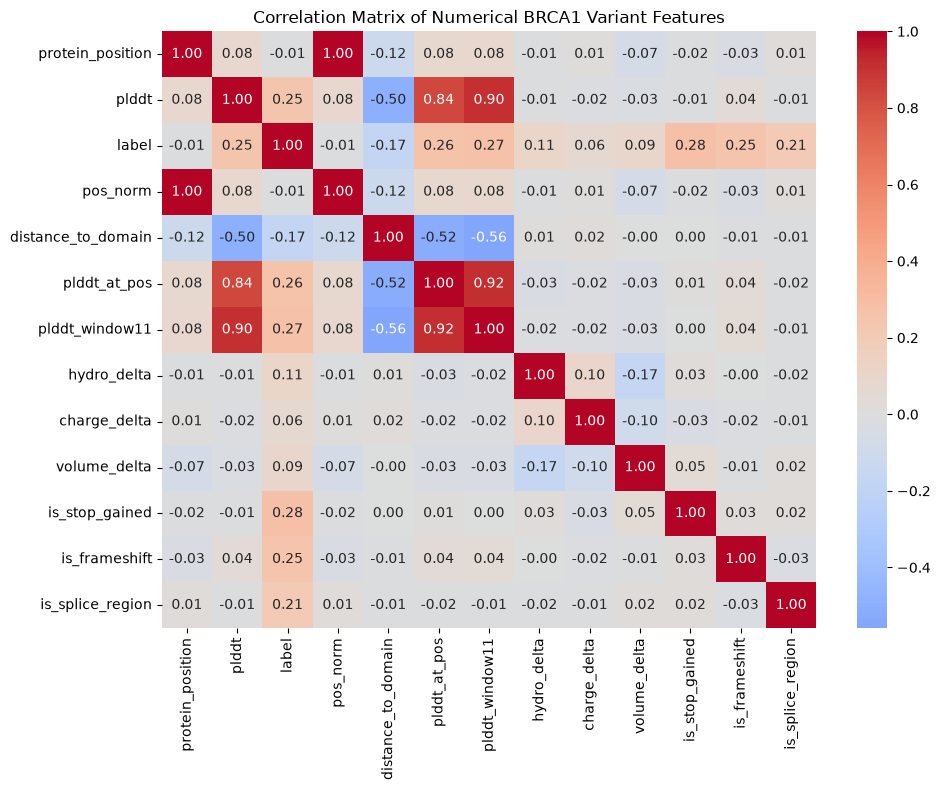

In [19]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix,annot=True,fmt=".2f",cmap="coolwarm",center=0)
plt.title("Correlation Matrix of Numerical BRCA1 Variant Features")
plt.tight_layout()
plt.show()

`protein_position` & `pos_norm` are perfectly correlated because `pos_norm` is derived from `protein_position / 1863`.

In [20]:
target_corr = (corr_matrix["label"].drop("label").sort_values(key=abs, ascending=False))
target_corr

is_stop_gained        0.275513
plddt_window11        0.274956
plddt_at_pos          0.258926
is_frameshift         0.252775
plddt                 0.250639
is_splice_region      0.208345
distance_to_domain   -0.174005
hydro_delta           0.107719
volume_delta          0.088079
charge_delta          0.064268
pos_norm             -0.012551
protein_position     -0.012551
Name: label, dtype: float64

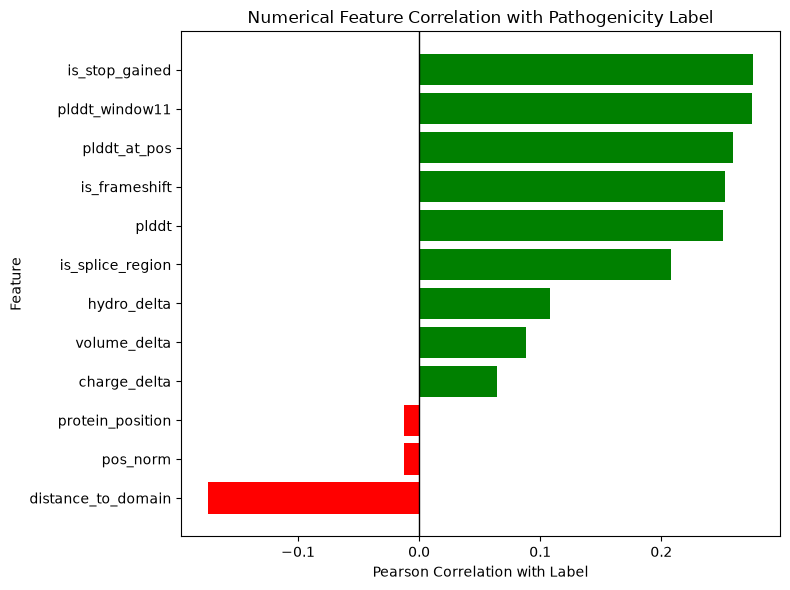

In [21]:
target_corr_sorted = target_corr.sort_values(ascending=True)
colors = ["green" if value > 0 else "red"for value in target_corr_sorted.values]
plt.figure(figsize=(8, 6))
plt.barh(target_corr_sorted.index,target_corr_sorted.values,color=colors)
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Pearson Correlation with Label")
plt.ylabel("Feature")
plt.title("Numerical Feature Correlation with Pathogenicity Label")
plt.tight_layout()
plt.show()

In [22]:
domain_summary = (df.groupby("domain").agg(n_variants=("variation_id", "count"),
                             pathogenic_rate=("label", "mean"),
                             mean_plddt=("plddt_at_pos", "mean"),
                             mean_hydro_delta=("hydro_delta", "mean"),
                             mean_charge_delta=("charge_delta", "mean"),
                             mean_volume_delta=("volume_delta", "mean")))

domain_summary["pathogenic_rate"] *= 100
domain_summary.round(2)

,n_variants,pathogenic_rate,mean_plddt,mean_hydro_delta,mean_charge_delta,mean_volume_delta
domain,,,,,,
BRCT1,75,72.00,89.83,3.73,0.48,41.64
BRCT2,90,64.44,80.09,3.38,0.43,43.19
OTHER,1337,35.00,52.14,3.51,0.48,48.69
RING,98,82.65,87.56,3.45,0.46,54.29


In [23]:
df.groupby("domain")[["is_stop_gained","is_frameshift","is_splice_region"]].mean().mul(100).round(1)

,is_stop_gained,is_frameshift,is_splice_region
domain,,,
BRCT1,8.0,9.3,6.7
BRCT2,8.9,8.9,4.4
OTHER,9.0,9.9,5.7
RING,9.2,15.3,5.1


In [24]:
eda_summary = (df.groupby("label").agg(n_variants=("variation_id", "count"),
                                       mean_position=("protein_position", "mean"),
                                       mean_distance_to_domain=("distance_to_domain", "mean"),
                                       mean_plddt_at_pos=("plddt_at_pos", "mean"),
                                       mean_plddt_window11=("plddt_window11", "mean"),
                                       mean_hydro_delta=("hydro_delta", "mean"),
                                       mean_charge_delta=("charge_delta", "mean"),
                                       mean_volume_delta=("volume_delta", "mean"),
                                       stop_gained_rate=("is_stop_gained", "mean"),
                                       frameshift_rate=("is_frameshift", "mean"),
                                       splice_region_rate=("is_splice_region", "mean")))

rate_cols = ["stop_gained_rate","frameshift_rate","splice_region_rate"]
eda_summary[rate_cols] = eda_summary[rate_cols] * 100
eda_summary.round(2)

,n_variants,mean_position,mean_distance_to_domain,mean_plddt_at_pos,mean_plddt_window11,mean_hydro_delta,mean_charge_delta,mean_volume_delta,stop_gained_rate,frameshift_rate,splice_region_rate
label,,,,,,,,,,,
0,939,940.77,342.90,54.44,54.39,3.28,0.45,45.92,2.34,3.73,1.60
1,661,926.88,256.56,62.21,61.96,3.82,0.52,51.89,18.31,19.21,11.35


## Protein position and labels

In [28]:
pos_label_counts = (df.groupby("protein_position")["label"].nunique())
pos_label_counts.value_counts().sort_index()

label
1    900
2    188
Name: count, dtype: int64

In [31]:
mixed_label_pos = pos_label_counts[pos_label_counts > 1]
df.loc[df["protein_position"].isin(mixed_label_pos.index),["protein_position","protein_change","domain","clinical_significance","label"]].sort_values("protein_position").head(10)

,protein_position,protein_change,domain,clinical_significance,label
628,7,p.A7W,RING,Likely pathogenic,1
216,7,p.K7D,RING,Likely benign,0
493,26,p.P26T,RING,Pathogenic,1
661,26,p.Q26D,RING,Likely benign,0
1034,40,p.A40D,RING,Likely benign,0
1251,40,p.N40Y,RING,Likely pathogenic,1
1542,44,p.A44E,RING,Benign,0
933,44,p.E44C,RING,Pathogenic,1
814,44,p.K44G,RING,Pathogenic,1
749,44,p.R44S,RING,Pathogenic,1


Hence, position alone cannot determine pathogenicity.

In [32]:
protein_change_labels = (df.groupby("protein_change")["label"].nunique())
protein_change_labels.value_counts().sort_index()

label
1    1599
Name: count, dtype: int64

In [33]:
conflicting_protein_changes = protein_change_labels[protein_change_labels > 1]
conflicting_protein_changes

Series([], Name: label, dtype: int64)

## Finding



### Target & Class structure:

- The binary target contains `939` benign/likely benign variants (58.7%) and `661` pathogenic/likely pathogenic variants (41.3%).
- The imbalance is moderate.

### Biologic patterns

- Pathogenic variants are disproportionately represented in the RING, BRCT1, and BRCT2 regions compared with OTHER.
- The relationship between pLDDT and pathogenicity needs more analysis as pLDDt varies with variants while pLDDT_at_pos seems to be directly associated to the protein position.



### Feature Relationships and Data Structure

- `pos_norm` is a deterministic rescaling of `protein_position` (protein_pos / 1863).
- Domain one-hot variables encode the same information as `domain`.
- `distance_to_domain` is derived from protein position and supplied domain boundaries.
- `plddt_at_pos` and `plddt_window11` are strongly related position-level structural information.
- Physicochemical delta features are deterministic properties of the reference-to-alternate amino-acid substitution.
- Multiple variants can occur at the same protein residue, which may be important for model and train/test split.